In [1]:
import sys
sys.path.append("..") # This is for the imports from adjacent folders to work
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import pandas as pd
plt.rcParams['text.usetex'] = True
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 200
#plt.rcParams.update({'font.size': 15})

from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import EstimatorV2
from qiskit import generate_preset_pass_manager
from hardware_aware_circuit import angles_from_circuit, build_pubs
from qiskit_aer import AerSimulator

In [2]:
service = QiskitRuntimeService(
    channel='ibm_quantum_platform',
    instance='crn:v1:bluemix:public:quantum-computing:eu-de:a/cb804b30dfcb48b890393bfd6e41e9c2:a59c3379-0cf7-47fe-adf1-553bf24e0c35::'
)
backend = service.backend("ibm_basquecountry")

In [3]:
#backend = AerSimulator(method='matrix_product_state')
backend = AerSimulator()
estimator = EstimatorV2(mode = backend)

n = 10
theta, p, k = 0.475, 0.0253, 10

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)

theta, lam = angles_from_circuit(theta, p)          
pubs, meta = build_pubs(n, k, theta, lam,
                        init_csv="../results/ckt_evolve_candA/initial_state_n10_cA.csv",
                        backend=backend, pass_manager=pm)

results = estimator.run(pubs).result()

In [15]:
meta[0]['observables']

['z_0',
 'z_1',
 'z_2',
 'z_3',
 'z_4',
 'z_5',
 'z_6',
 'z_7',
 'z_8',
 'z_9',
 'mz',
 'zz_0',
 'zz_1',
 'zz_2',
 'zz_3',
 'zz_4',
 'zz_5',
 'zz_6',
 'zz_7',
 'zz_8',
 'zz_nn',
 'zz_center']

In [ ]:
len(results[0].data.evs)

11

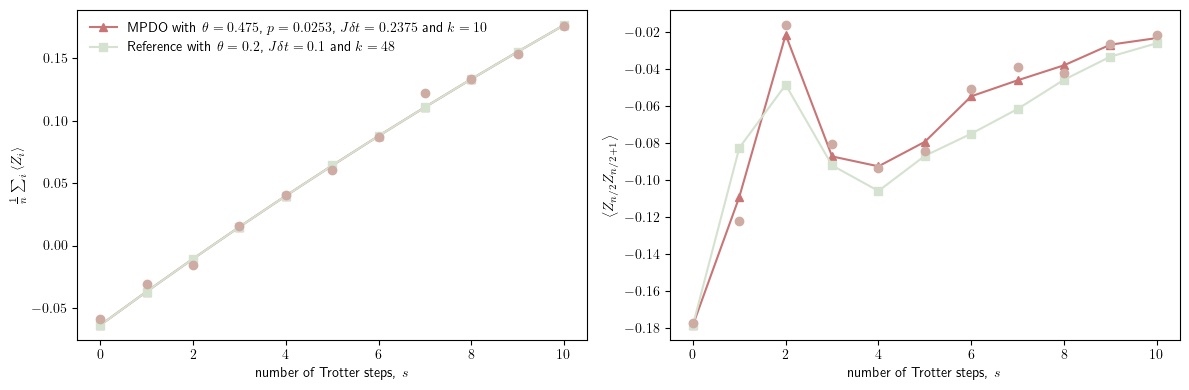

In [16]:
df = pd.read_csv(f'../results/ckt_evolve_candA/evolve_n10_k10_cA.csv') 
steps = df["step"]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

colors = ["#c87576", "#d4e2cf", "#ceaca3"]
legends = ["MPDO with $\\theta = 0.475$, $p=0.0253$, $J\\delta t = 0.2375$ and $k=10$", "Reference with $\\theta = 0.2$, $J\\delta t = 0.1$ and $k=48$"]
labels = ["trot", "ref"]
markers = ["^", "s", "o"]
for (idx, l) in enumerate(labels):
    mean_mag = df[f"mz_{l}"]
    corr = df[f"zz_nn_{l}"]
    axes[0].plot(steps, mean_mag, color = colors[idx], marker = markers[idx], linestyle = "solid", label = legends[idx])
    axes[1].plot(steps, corr, color = colors[idx], marker = markers[idx], linestyle = "solid", label = legends[idx])

idx_mz = meta[0]['observables'].index('mz')
idx_zz_nn = meta[0]['observables'].index('zz_nn')

for (idx, res) in enumerate(results):
    axes[0].plot(steps[idx], res.data.evs[idx_mz], color = colors[2], marker = markers[2], linestyle = "none")
    axes[1].plot(steps[idx], res.data.evs[idx_zz_nn], color = colors[2], marker = markers[2], linestyle = "none")

axes[0].set_ylabel(r"$\frac{1}{n} \sum_i \left\langle Z_i \right\rangle$")
axes[0].set_xlabel(r"number of Trotter steps, $s$")
axes[0].legend(frameon = False)

axes[1].set_ylabel(r"$\left\langle Z_{n/2} Z_{n/2 + 1} \right\rangle$")
axes[1].set_xlabel(r"number of Trotter steps, $s$")

plt.tight_layout()
# plt.savefig(f'../results/validation_qiskit_mpdo.png', bbox_inches='tight', transparent = True)
plt.show()